## 0 - Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold, GridSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'font.size': 11, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

CLASS_COLORS = {0: '#2E86AB', 1: '#E63946'}
CLASS_LABELS = {0: 'No Disease (0)', 1: 'Disease (1)'}

def heatmap_cm(y_true, y_pred, ax, title=''):
    """Annotated confusion-matrix heatmap. Rows = true, cols = predicted."""
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=[CLASS_LABELS[0], CLASS_LABELS[1]],
                yticklabels=[CLASS_LABELS[0], CLASS_LABELS[1]], ax=ax,
                linewidths=0.8, linecolor='white',
                annot_kws={'size': 14, 'weight': 'bold'})
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    if title: ax.set_title(title)


## 1 - Data Loading

In [2]:
df = pd.read_csv('./heart_disease.csv')
df.head()


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up,0


In [3]:
print('Shape:', df.shape)
df.dtypes


Shape: (918, 12)


Age                 int64
Sex                   str
ChestPainType         str
RestingBP         float64
Cholesterol       float64
FastingBS           int64
RestingECG            str
MaxHR             float64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
RestingBP,914.0,132.423414,18.474195,0.0,120.0,130.0,140.0,200.0
Cholesterol,915.0,198.702732,109.497795,0.0,173.5,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
MaxHR,916.0,136.804585,25.456660,60.0,120.0,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.0,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.0,1.0,1.0,1.0


In [5]:
df.isnull().sum()


Age               0
Sex               0
ChestPainType     0
RestingBP         4
Cholesterol       3
FastingBS         0
RestingECG        0
MaxHR             2
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

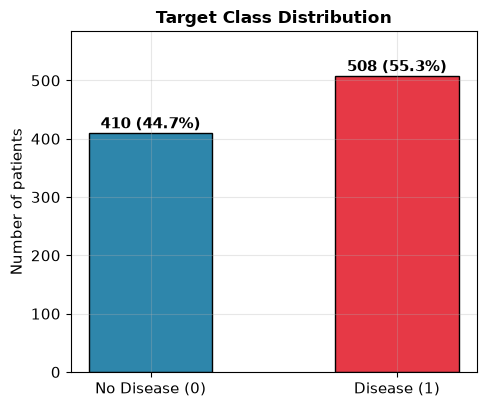

In [6]:
# --- Class balance: a 55% / 45% split is mild imbalance, good for SVM ---
fig, ax = plt.subplots(figsize=(5, 4.2))
counts = df['HeartDisease'].value_counts().sort_index()
bars = ax.bar([CLASS_LABELS[i] for i in counts.index], counts.values,
    color=[CLASS_COLORS[i] for i in counts.index], width=0.5, edgecolor='black')
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 8, f'{v} ({v/len(df):.1%})', ha='center', fontweight='bold')
ax.set_title('Target Class Distribution')
ax.set_ylabel('Number of patients')
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()


NaNs in RestingBP and Cholesterol. Filled with column median.

In [7]:
df["RestingBP"] = df["RestingBP"].fillna(df["RestingBP"].median())
df["Cholesterol"] = df["Cholesterol"].fillna(df["Cholesterol"].median())
df["MaxHR"] = df["MaxHR"].fillna(df["MaxHR"].median())
print("Missing values after imputation:", df.isnull().sum().sum())


Missing values after imputation: 0


Density of each numeric feature by class.

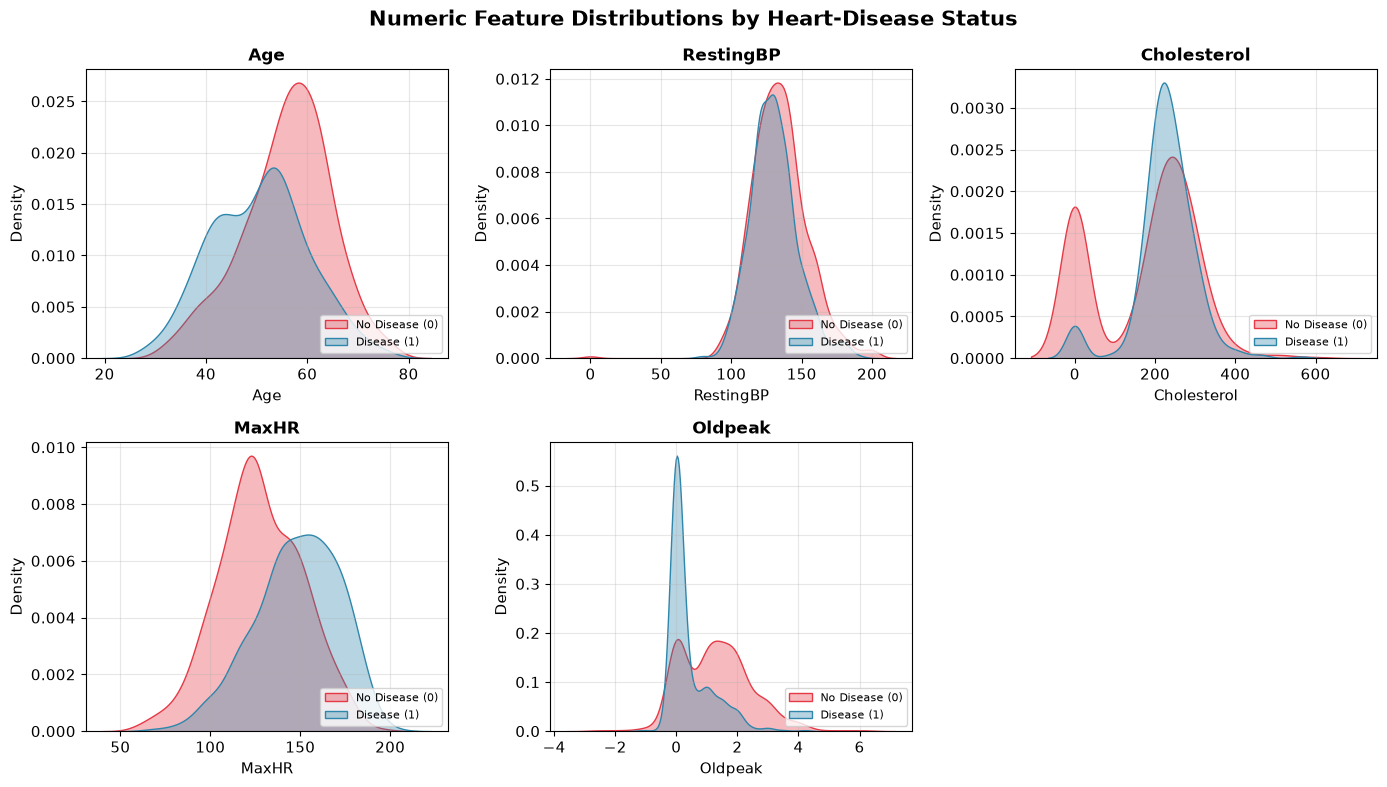

In [8]:
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(14, 8), squeeze=False)
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.kdeplot(data=df, x=col, hue='HeartDisease', hue_order=[0, 1],
                palette=[CLASS_COLORS[0], CLASS_COLORS[1]],
                fill=True, alpha=0.35, ax=ax)
    ax.set_title(col)
    ax.legend(title=None, labels=[CLASS_LABELS[0], CLASS_LABELS[1]], fontsize=8, loc='lower right')
axes[1, 2].axis('off')
fig.suptitle('Numeric Feature Distributions by Heart-Disease Status', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()


Count of each categorical value by class.

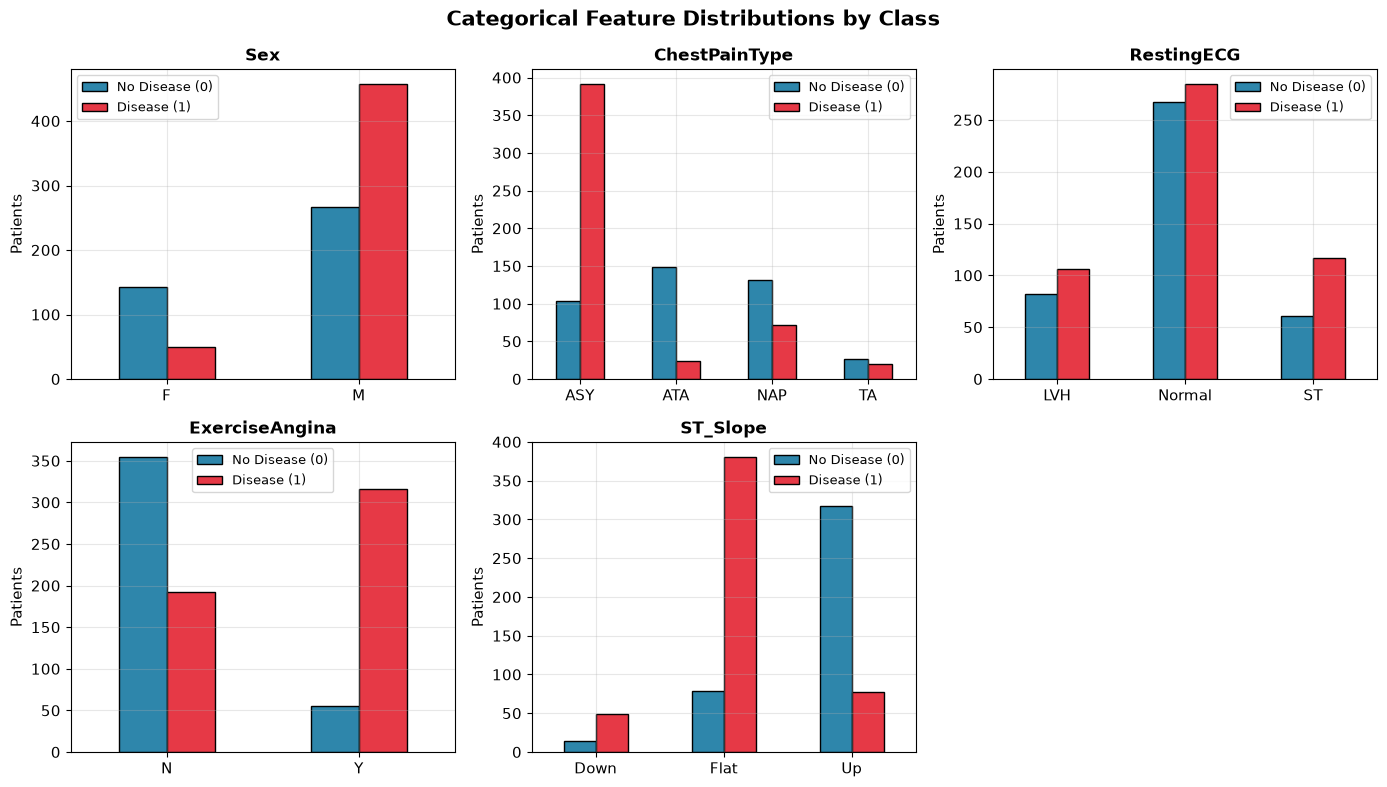

In [9]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
fig, axes = plt.subplots(2, 3, figsize=(14, 8), squeeze=False)
for ax, col in zip(axes.ravel(), cat_cols):
    ct = pd.crosstab(df[col], df['HeartDisease'])
    ct.plot(kind='bar', ax=ax, color=[CLASS_COLORS[0], CLASS_COLORS[1]], edgecolor='black', rot=0)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Patients')
    ax.legend(title=None, labels=[CLASS_LABELS[0], CLASS_LABELS[1]], fontsize=9)
axes[1, 2].axis('off')
fig.suptitle('Categorical Feature Distributions by Class', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()


In [10]:
numeric_features = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
categorical_features = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)


Train: (734, 11) | Test: (184, 11)


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
    ])
X_train_proc = pd.DataFrame(preprocessor.fit_transform(X_train), index=X_train.index)
X_test_proc = pd.DataFrame(preprocessor.transform(X_test), index=X_test.index)
print('Processed shape:', X_train_proc.shape)
print(X_train_proc.head(2))


Processed shape: (734, 20)
           0         1         2         3         4         5    6    7   \
485  0.970012  0.339813  0.127021  1.835497 -0.326090  0.317046  0.0  1.0   
486  0.122028 -1.274393  0.182408  1.835497  1.689488 -0.440356  0.0  1.0   

      8    9    10   11   12   13   14   15   16   17   18   19  
485  0.0  1.0  0.0  0.0  0.0  0.0  1.0  0.0  1.0  0.0  1.0  0.0  
486  0.0  1.0  0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0  0.0  1.0  


## 2 - Preprocessing

One-hot encode categoricals, standardize numerics, 80/20 train/test split.

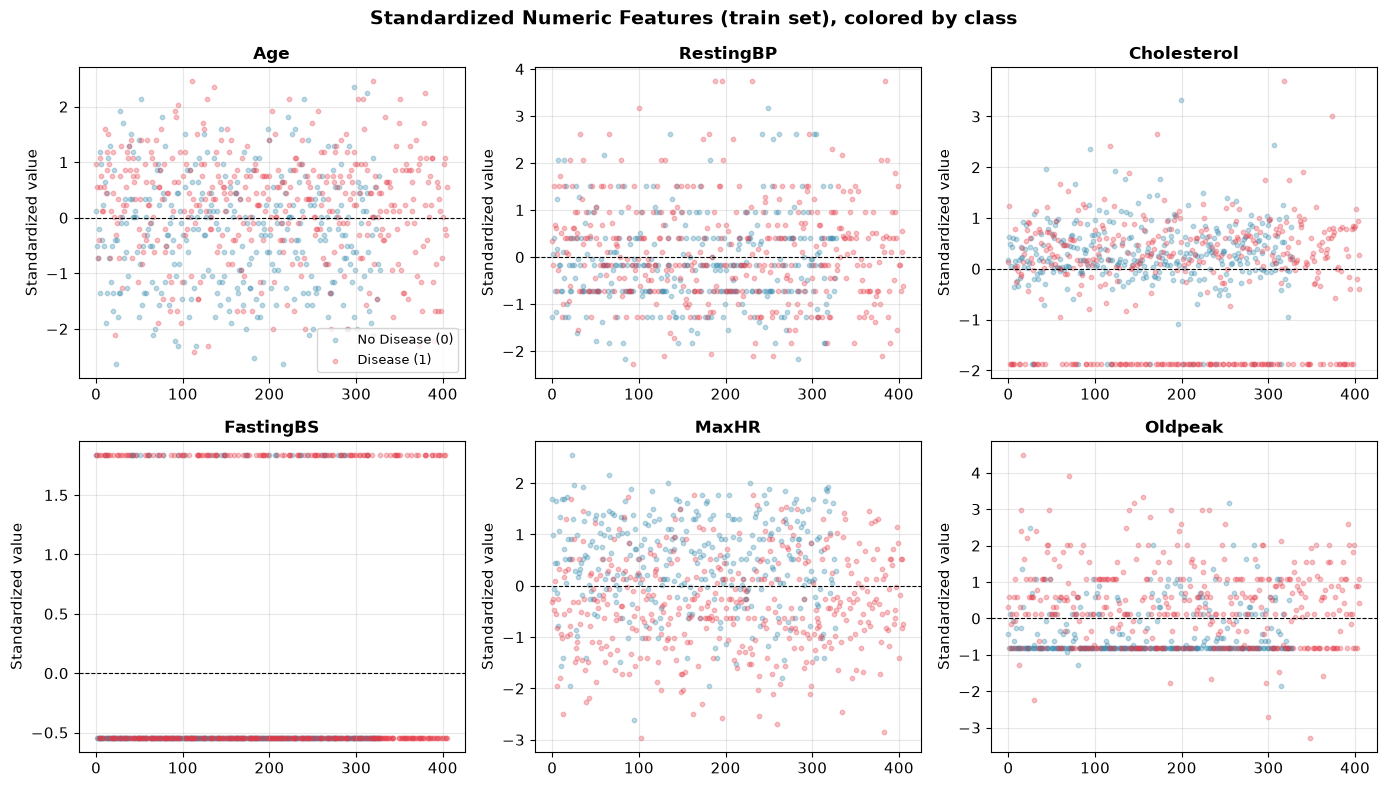

In [12]:
import numpy as np
fig, axes = plt.subplots(2, 3, figsize=(14, 8), squeeze=False)
for idx, col in enumerate(numeric_features):
                ax = axes.ravel()[idx]
                vals = X_train_proc.iloc[:, idx].values
                for cls, color in CLASS_COLORS.items():
                                mask = (y_train.values == cls)
                                ax.scatter(np.arange(mask.sum()), vals[mask], s=10, alpha=0.3, color=color, edgecolor=None,
            label=CLASS_LABELS[cls] if col == 'Age' else None)
                ax.set_title(col)
                ax.set_xlabel('')
                ax.set_ylabel('Standardized value')
                ax.axhline(0, color='black', lw=0.8, ls='--')
                if col == 'Age':
                                ax.legend(fontsize=9)
fig.suptitle('Standardized Numeric Features (train set), colored by class', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


## 3 - Baseline SVMs

Kernel math:
- linear: k(x,x) = x.x
- rbf: k(x,x) = exp(-gamma * |x-x|^2)
- poly: k(x,x) = (gamma * x.x + r)^d, d=3
- sigmoid: k(x,x) = tanh(gamma * x.x + r)

All use C=1.

In [13]:
KERNELS = {
    'linear': dict(kernel='linear'),
    'rbf': dict(kernel='rbf'),
    'poly': dict(kernel='poly', degree=3),
    'sigmoid': dict(kernel='sigmoid'),
}
def evaluate(model, X, y_true):
    y_pred = model.predict(X)
    return {
    'Accuracy': accuracy_score(y_true, y_pred),
    'Precision': precision_score(y_true, y_pred),
    'Recall': recall_score(y_true, y_pred),
    'F1': f1_score(y_true, y_pred),
    'ROC AUC': roc_auc_score(y_true, model.decision_function(X)),
    'y_pred': y_pred,
    }
models, results = {}, {}
for name, params in KERNELS.items():
    m = SVC(random_state=42, **params)
    m.fit(X_train_proc, y_train)
    models[name] = m
    results[name] = evaluate(m, X_test_proc, y_test)
    print(f'{name:8s} -> Accuracy {results[name]["Accuracy"]:.4f} | F1 {results[name]["F1"]:.4f} | support vectors {len(m.support_vectors_)}')


linear   -> Accuracy 0.8750 | F1 0.8920 | support vectors 251
rbf      -> Accuracy 0.8967 | F1 0.9091 | support vectors 307
poly     -> Accuracy 0.8750 | F1 0.8878 | support vectors 315
sigmoid  -> Accuracy 0.7989 | F1 0.8213 | support vectors 243


### 3.1 Classification reports

In [14]:
for name in KERNELS:
    tp = (y_test == 1); pred = (results[name]['y_pred'] == 1)
    tn = (~tp) & (~pred); fn = (~tp) & (pred)
    fp = tp & (~pred)
    print(f'=== SVM ({name}) ===')
    print(f' TP={tp.sum()} FP={fp.sum()} FN={fn.sum()} TN={tn.sum()}')
    print(f' Accuracy={results[name]["Accuracy"]:.4f} Precision={results[name]["Precision"]:.4f} '
    f'Recall={results[name]["Recall"]:.4f} F1={results[name]["F1"]:.4f}')
    print()


=== SVM (linear) ===
 TP=102 FP=7 FN=16 TN=66
 Accuracy=0.8750 Precision=0.8559 Recall=0.9314 F1=0.8920

=== SVM (rbf) ===
 TP=102 FP=7 FN=12 TN=70
 Accuracy=0.8967 Precision=0.8879 Recall=0.9314 F1=0.9091

=== SVM (poly) ===
 TP=102 FP=11 FN=12 TN=70
 Accuracy=0.8750 Precision=0.8835 Recall=0.8922 F1=0.8878

=== SVM (sigmoid) ===
 TP=102 FP=17 FN=20 TN=62
 Accuracy=0.7989 Precision=0.8095 Recall=0.8333 F1=0.8213



### 3.2 Confusion matrix heatmaps

Rows = true, columns = predicted.

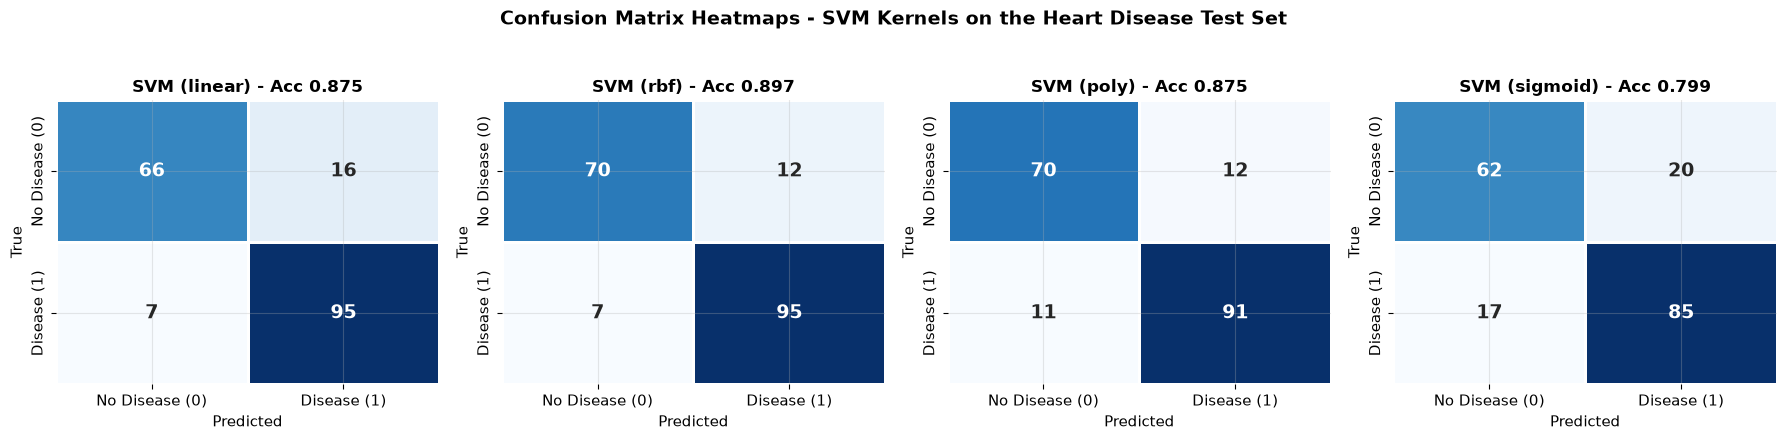

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), squeeze=False)
for ax, name in zip(axes.ravel(), KERNELS):
    heatmap_cm(y_test, results[name]['y_pred'], ax,
    f'SVM ({name}) - Acc {results[name]["Accuracy"]:.3f}')
plt.suptitle('Confusion Matrix Heatmaps - SVM Kernels on the Heart Disease Test Set', fontsize=14, fontweight='bold', y=1.04)
plt.tight_layout(); plt.show()


## 4 - Kernel Comparison


         Accuracy  Precision  Recall      F1  ROC AUC
rbf        0.8967     0.8879  0.9314  0.9091   0.9495
linear     0.8750     0.8559  0.9314  0.8920   0.9313
poly       0.8750     0.8835  0.8922  0.8878   0.9450
sigmoid    0.7989     0.8095  0.8333  0.8213   0.8253


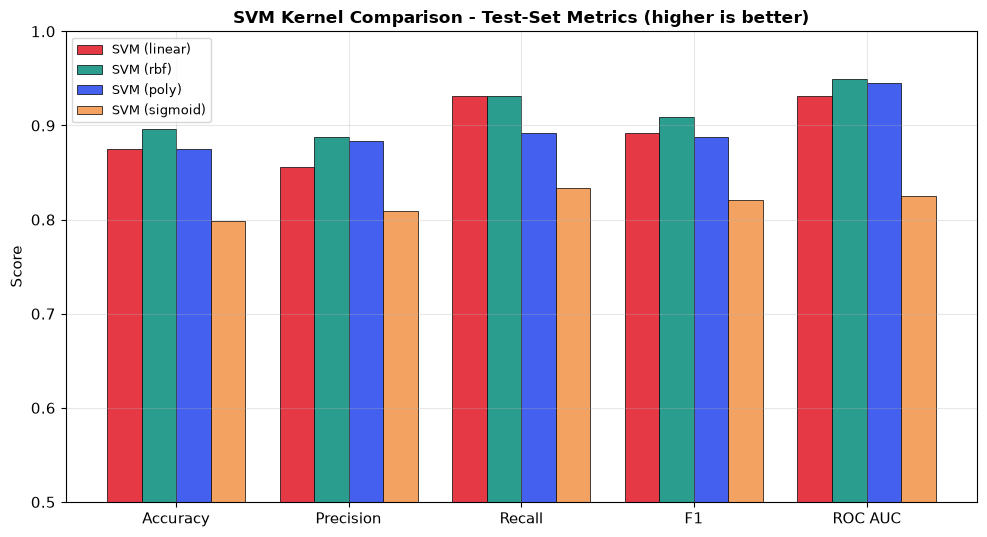

In [16]:
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']
comp_df = pd.DataFrame({name: {m: results[name][m] for m in metric_cols} for name in KERNELS}).T
comp_df = comp_df.sort_values('F1', ascending=False)
print(comp_df.round(4))
fig, ax = plt.subplots(figsize=(10, 5.5))
palette = sns.color_palette(['#E63946', '#2A9D8F', '#4361EE', '#F4A261'])
x = np.arange(len(metric_cols)); w = 0.8 / len(KERNELS)
for i, name in enumerate(KERNELS):
    ax.bar(x + (i - 1.5) * w, comp_df.loc[name, metric_cols], width=w,
    label=f'SVM ({name})', color=palette[i], edgecolor='black', linewidth=0.5)
ax.set_xticks(x, metric_cols)
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.0)
ax.set_title('SVM Kernel Comparison - Test-Set Metrics (higher is better)')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


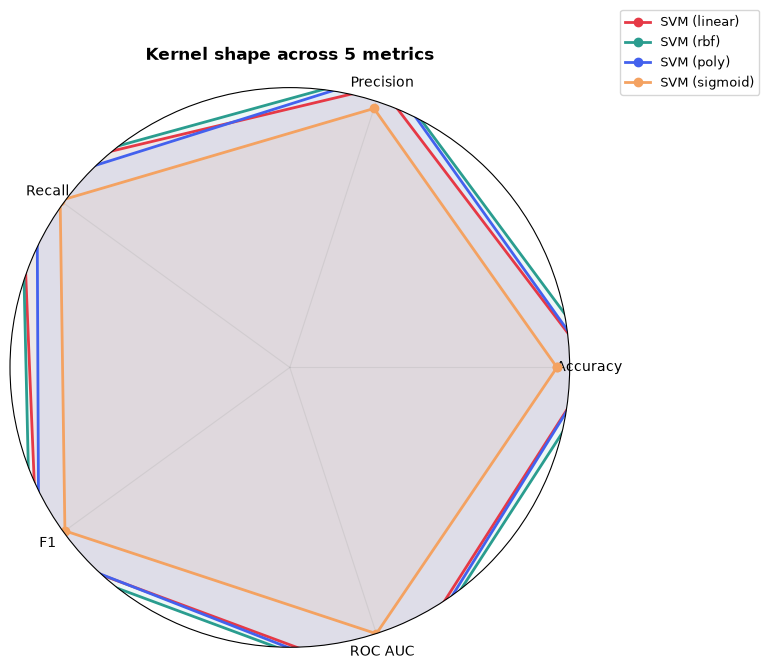

In [17]:
# Radar chart: one polygon per kernel
metrics = metric_cols
angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
palette = sns.color_palette(["#E63946", "#2A9D8F", "#4361EE", "#F4A261"])
for i, name in enumerate(KERNELS):
    vals = comp_df.loc[name, metrics].tolist()
    vals += vals[:1]
    vals_norm = [0.5 + (v - 0.5) / 0.5 for v in vals]
    ax.plot(angles, vals_norm, "o-", linewidth=2, label=f"SVM ({name})", color=palette[i])
    ax.fill(angles, vals_norm, alpha=0.08, color=palette[i])
ax.set_xticks(angles[:-1], metrics)
ax.tick_params(axis='x', labelsize=10)
ax.set_ylim(0, 1.15)
ax.set_yticks([])
ax.set_rlabel_position(0)
ax.set_title("Kernel shape across 5 metrics", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=9)
plt.tight_layout(); plt.show()


In [18]:
# --- Ranking table with winner highlighted ---
ranking = comp_df.copy()
ranking.insert(0, 'Rank', range(1, len(ranking)+1))
ranking = ranking.sort_values('F1', ascending=False).reset_index(drop=True)
ranking.index += 1
ranking


,Rank,Accuracy,Precision,Recall,F1,ROC AUC
1,1,0.896739,0.887850,0.931373,0.909091,0.949546
2,2,0.875000,0.855856,0.931373,0.892019,0.931253
3,3,0.875000,0.883495,0.892157,0.887805,0.945002
4,4,0.798913,0.809524,0.833333,0.821256,0.825323


RBF is the strongest kernel. Linear is simplest. Poly (deg 3) is close to RBF. Sigmoid is weakest.

## 5 - PCA

Reduce features, then train SVMs on the reduced space.

In [19]:
# Fit PCA on the scaled numeric features (the continuous ones are the meaningful variance)
X_num_scaled = StandardScaler().fit_transform(X_train[numeric_features].values)
pca_full = PCA(random_state=42)
pca_full.fit(X_num_scaled)
evr = pca_full.explained_variance_ratio_
print('Explained variance ratio per component:')
for i, v in enumerate(evr, 1):
    print(f' PC{i}: {v:.3f} (cumulative {np.cumsum(evr)[i-1]:.3f})')
print(f' Components needed for 95% variance: {np.argmax(np.cumsum(evr) >= 0.95) + 1}')


Explained variance ratio per component:
 PC1: 0.304 (cumulative 0.304)
 PC2: 0.215 (cumulative 0.519)
 PC3: 0.146 (cumulative 0.665)
 PC4: 0.139 (cumulative 0.804)
 PC5: 0.107 (cumulative 0.912)
 PC6: 0.088 (cumulative 1.000)
 Components needed for 95% variance: 6


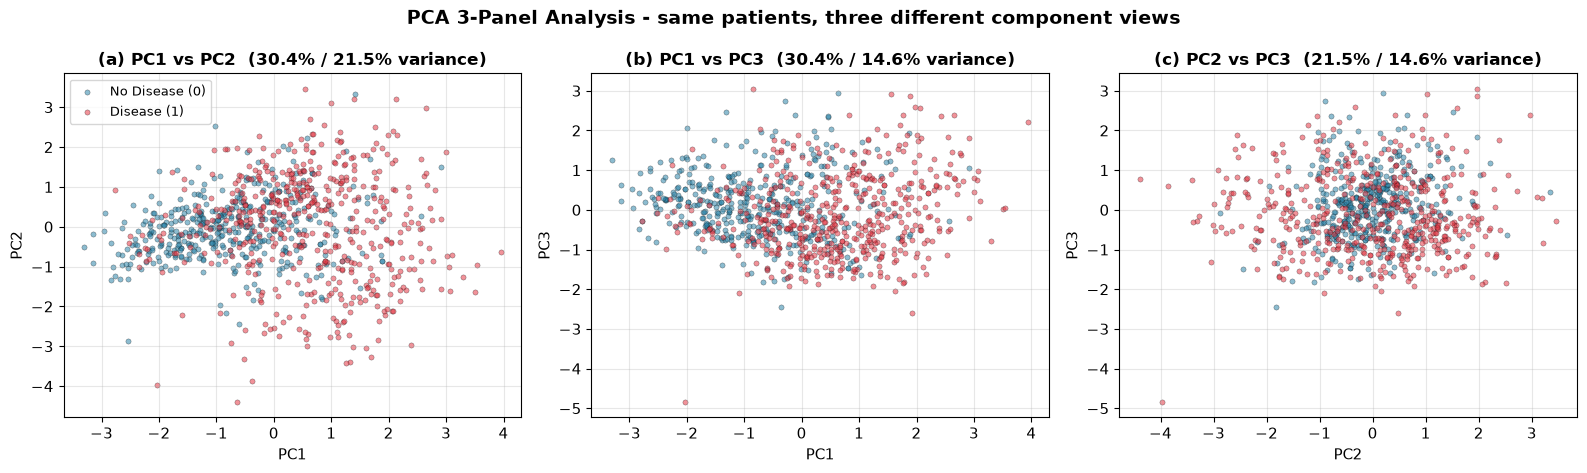

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), squeeze=False)
X_all_num_scaled = StandardScaler().fit(X_train[numeric_features].values).transform(X[numeric_features].values)
proj = pca_full.transform(X_all_num_scaled)
panels = [('PC1', 'PC2'), ('PC1', 'PC3'), ('PC2', 'PC3')]
titles = ['(a) PC1 vs PC2', '(b) PC1 vs PC3', '(c) PC2 vs PC3']
for ax, (xi, yi), t in zip(axes.ravel(), panels, titles):
    ix = {'PC1': 0, 'PC2': 1, 'PC3': 2}[xi]
    iy = {'PC1': 0, 'PC2': 1, 'PC3': 2}[yi]
    for cls, color in CLASS_COLORS.items():
        sub = proj[y.values == cls]
        ax.scatter(sub[:, ix], sub[:, iy], s=14, alpha=0.55, color=color,
                   edgecolor='black', linewidth=0.3, label=CLASS_LABELS[cls])
    ax.set_title(f'{t}  ({evr[ix]:.1%} / {evr[iy]:.1%} variance)')
    ax.set_xlabel(xi); ax.set_ylabel(yi)
    if t == '(a) PC1 vs PC2':
        ax.legend(fontsize=9)
fig.suptitle('PCA 3-Panel Analysis - same patients, three different component views', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


In [21]:
# Which 2-component PCA subset carries the most class signal?
Xs = StandardScaler().fit(X_train[numeric_features]).transform(X[numeric_features])
P = pca_full.transform(Xs)
n_train = len(X_train)
pairs = [(0,1), (0,2), (1,2)]
names = ["PC1+PC2", "PC1+PC3", "PC2+PC3"]
accs = []
for (i, j), n in zip(pairs, names):
    m = SVC(kernel="rbf", random_state=42).fit(P[:n_train][:, [i,j]], y_train.values)
    acc = accuracy_score(y_test.values, m.predict(P[n_train:][:, [i,j]]))
    accs.append((n, acc))
    print(f"SVM (RBF) on {n}: Accuracy {acc:.4f}")
print("Best 2-component subset:", max(accs, key=lambda t: t[1])[0])


SVM (RBF) on PC1+PC2: Accuracy 0.5489
SVM (RBF) on PC1+PC3: Accuracy 0.5489
SVM (RBF) on PC2+PC3: Accuracy 0.5652
Best 2-component subset: PC2+PC3


### 5.1 PCA to 2 components + decision boundaries

Explained variance of 2 PCs: 0.519


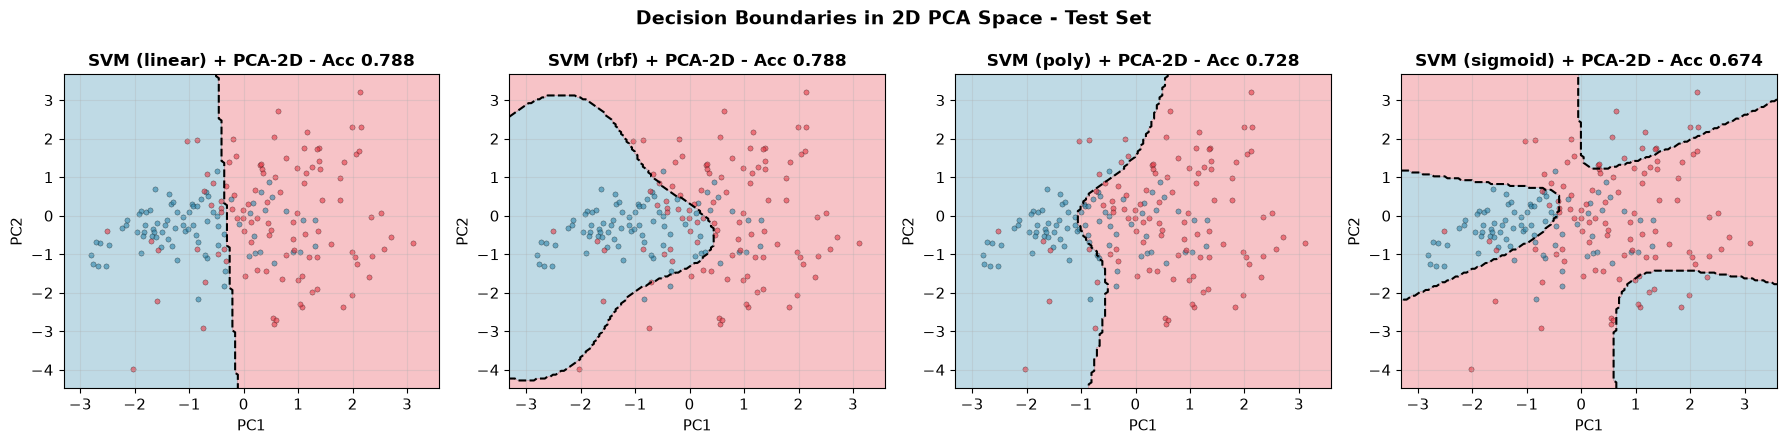

In [22]:
pca2 = PCA(n_components=2, random_state=42)
Xs = StandardScaler().fit_transform(X_train[numeric_features].values)
P_train = pca2.fit_transform(Xs)
Xs_test = StandardScaler().fit(X_train[numeric_features]).transform(X_test[numeric_features].values)
P_test = pca2.transform(Xs_test)
print(f'Explained variance of 2 PCs: {pca2.explained_variance_ratio_.sum():.3f}')

def plot_boundary(model, X, y, ax, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-1, 0, 1], alpha=0.3,
                colors=[CLASS_COLORS[0], CLASS_COLORS[1], 'white'])
    ax.contour(xx, yy, Z, levels=[0], colors='black', linewidths=1.5, linestyles='--')
    for cls, color in CLASS_COLORS.items():
        sub = X[y.values == cls]
        ax.scatter(sub[:, 0], sub[:, 1], s=14, alpha=0.6, color=color, edgecolor='black', linewidth=0.3)
    ax.set_title(f'{title} - Acc {accuracy_score(y, model.predict(X)):.3f}')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), squeeze=False)
pca_models = {}
for ax, (name, params) in zip(axes.ravel(), KERNELS.items()):
    m = SVC(random_state=42, **params)
    m.fit(P_train, y_train)
    pca_models[name] = m
    plot_boundary(m, P_test, y_test, ax, f'SVM ({name}) + PCA-2D')
plt.suptitle('Decision Boundaries in 2D PCA Space - Test Set', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


In [23]:
# --- PCA + kernel results table ---
pca_res = {}
for name in KERNELS:
    y_pred = pca_models[name].predict(P_test)
    pca_res[name] = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    }
pca_df = pd.DataFrame(pca_res).T.round(4)
print('SVM + PCA (2 components) results:')
pca_df


SVM + PCA (2 components) results:


,Accuracy,Precision,Recall,F1
linear,0.7880,0.8119,0.8039,0.8079
rbf,0.7880,0.8387,0.7647,0.8000
poly,0.7283,0.7097,0.8627,0.7788
sigmoid,0.6739,0.7059,0.7059,0.7059


### 5.2 Decision boundaries in raw 2D (Age vs MaxHR)

Raw 2D features, then the same after PCA.

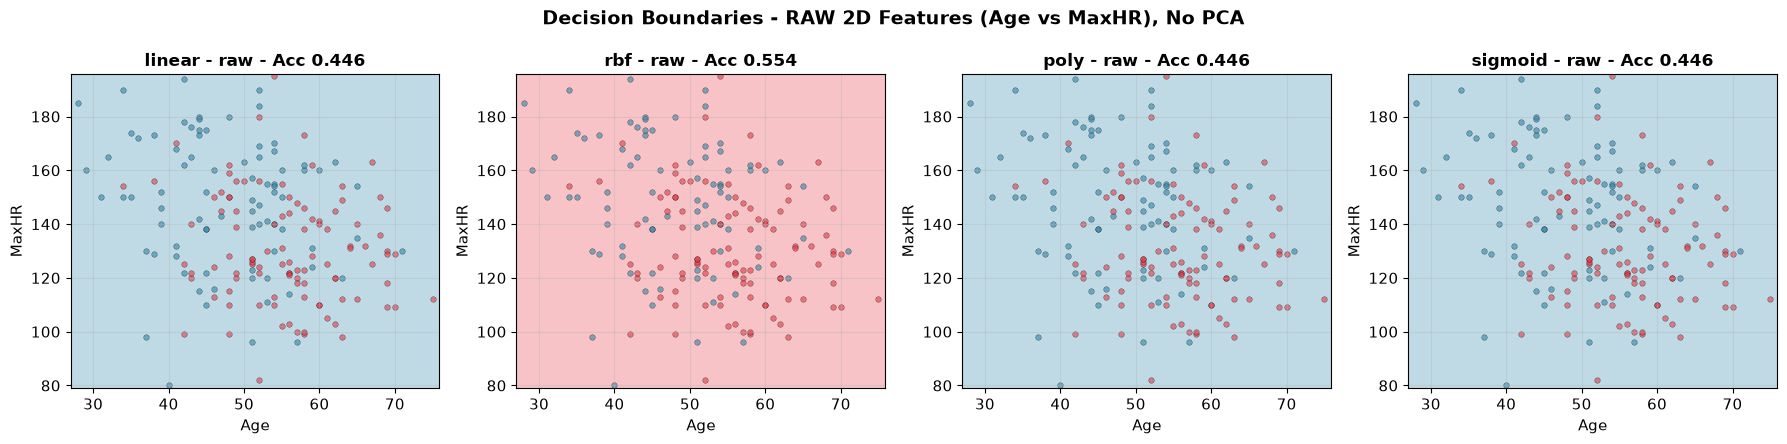

In [24]:
raw_cols = ['Age', 'MaxHR']
X2d_train = X_train[raw_cols].values
X2d_test  = X_test[raw_cols].values
sc2 = StandardScaler()
X2d_tr_s = sc2.fit_transform(X2d_train)
X2d_te_s = sc2.transform(X2d_test)

def plot_boundary2(model, X_plot, y_plot, ax, title, xlab, ylab):
                x_min, x_max = X_plot[:,0].min()-1, X_plot[:,0].max()+1
                y_min, y_max = X_plot[:,1].min()-1, X_plot[:,1].max()+1
                xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.3), np.arange(y_min, y_max, 0.3))
                Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
                ax.contourf(xx, yy, Z, levels=[-1, 0, 1], alpha=0.3, colors=[CLASS_COLORS[0], CLASS_COLORS[1], 'white'])
                ax.contour(xx, yy, Z, levels=[0], colors='black', linewidths=1.5, linestyles='--')
                for cls, color in CLASS_COLORS.items():
                                sub = X_plot[y_plot.values == cls]
                                ax.scatter(sub[:,0], sub[:,1], s=16, alpha=0.6, color=color, edgecolor='black', linewidth=0.3)
                ax.set_title(f'{title} - Acc {accuracy_score(y_plot, model.predict(X_plot)):.3f}')
                ax.set_xlabel(xlab); ax.set_ylabel(ylab)

raw_models = {}
for name, params in KERNELS.items():
                m = SVC(random_state=42, **params)
                m.fit(X2d_tr_s, y_train)
                raw_models[name] = m

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), squeeze=False)
for ax, name in zip(axes.ravel(), KERNELS):
                plot_boundary2(raw_models[name], X2d_test, y_test, ax,
        f'{name} - raw', 'Age', 'MaxHR')
plt.suptitle('Decision Boundaries - RAW 2D Features (Age vs MaxHR), No PCA', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


PCA on raw 2D features - explained variance: [0.699 0.301]


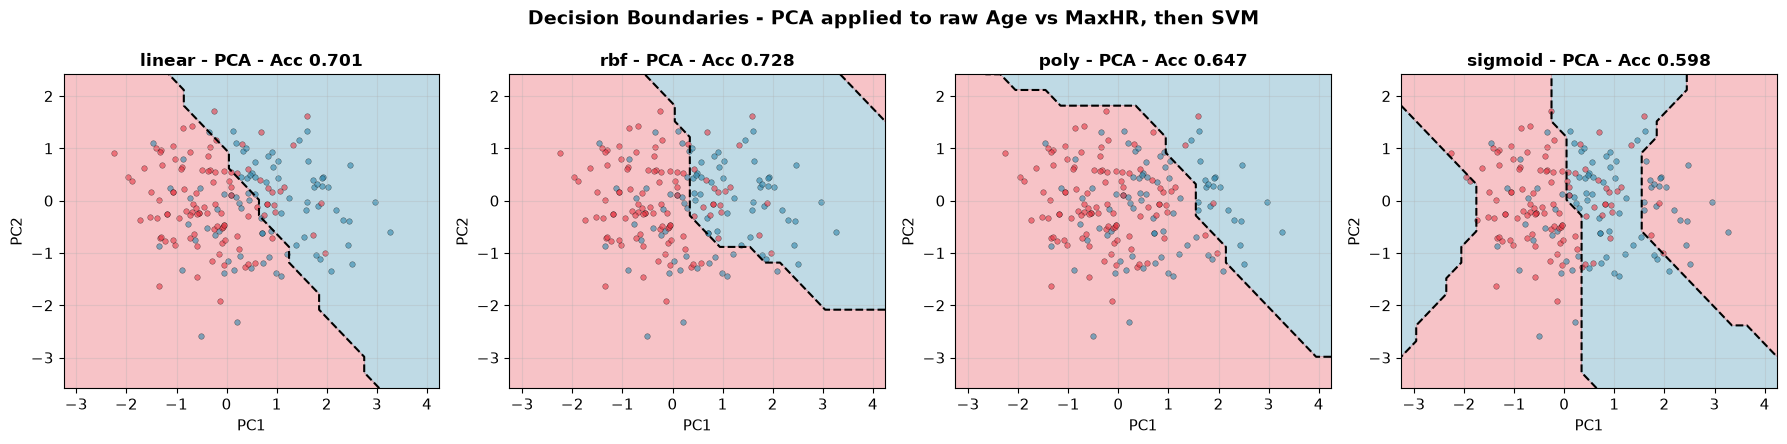

In [25]:
# Fit PCA on the 2 raw features (Age, MaxHR) so we keep a 2D output we can draw.
pca_raw2 = PCA(n_components=2, random_state=42)
P_train = pca_raw2.fit_transform(X2d_tr_s)
P_test  = pca_raw2.transform(X2d_te_s)
print(f'PCA on raw 2D features - explained variance: {pca_raw2.explained_variance_ratio_.round(3)}')
pca_raw_models = {}
for name, params in KERNELS.items():
    m = SVC(random_state=42, **params)
    m.fit(P_train, y_train)
    pca_raw_models[name] = m

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), squeeze=False)
for ax, name in zip(axes.ravel(), KERNELS):
    plot_boundary2(pca_raw_models[name], P_test, y_test, ax,
                   f'{name} - PCA', 'PC1', 'PC2')
plt.suptitle('Decision Boundaries - PCA applied to raw Age vs MaxHR, then SVM', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


Linear gives a flat line, RBF and poly give curved boundaries, sigmoid struggles.

### 5.3 Per-kernel before/after PCA

Left: confusion heatmap without PCA. Right: confusion heatmap after PCA. Below: decision boundaries in 2D PCA space.

PCA (2 components) explained variance: [0.304 0.215]


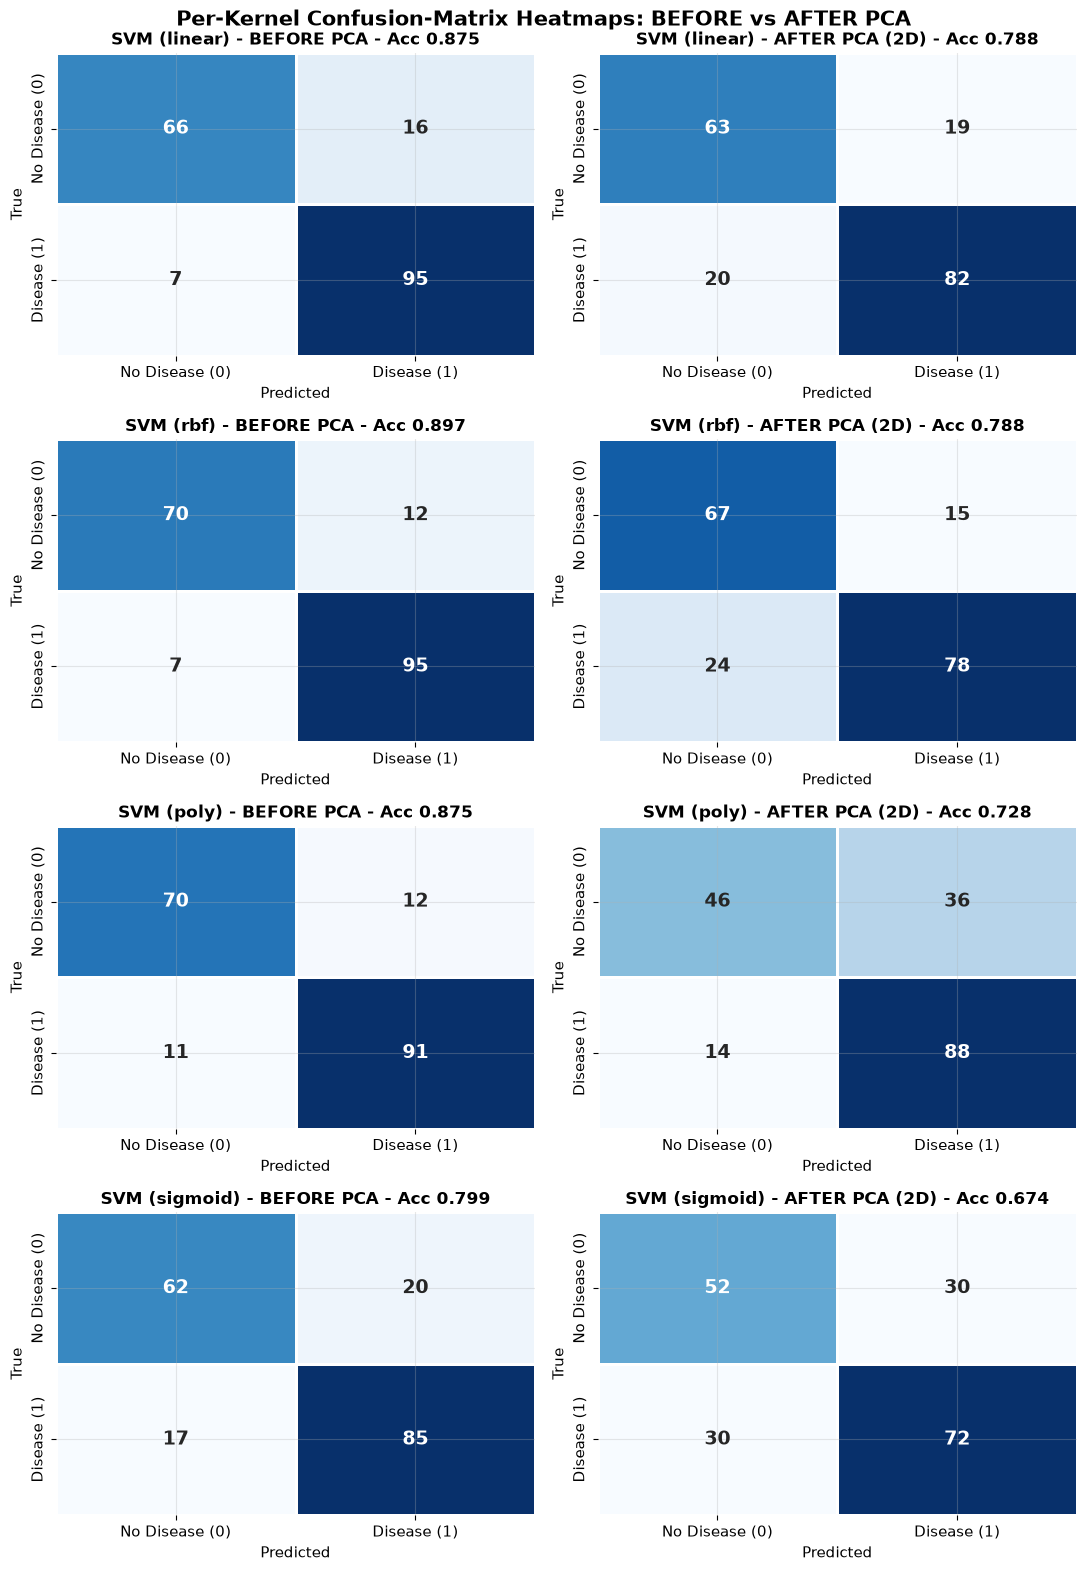

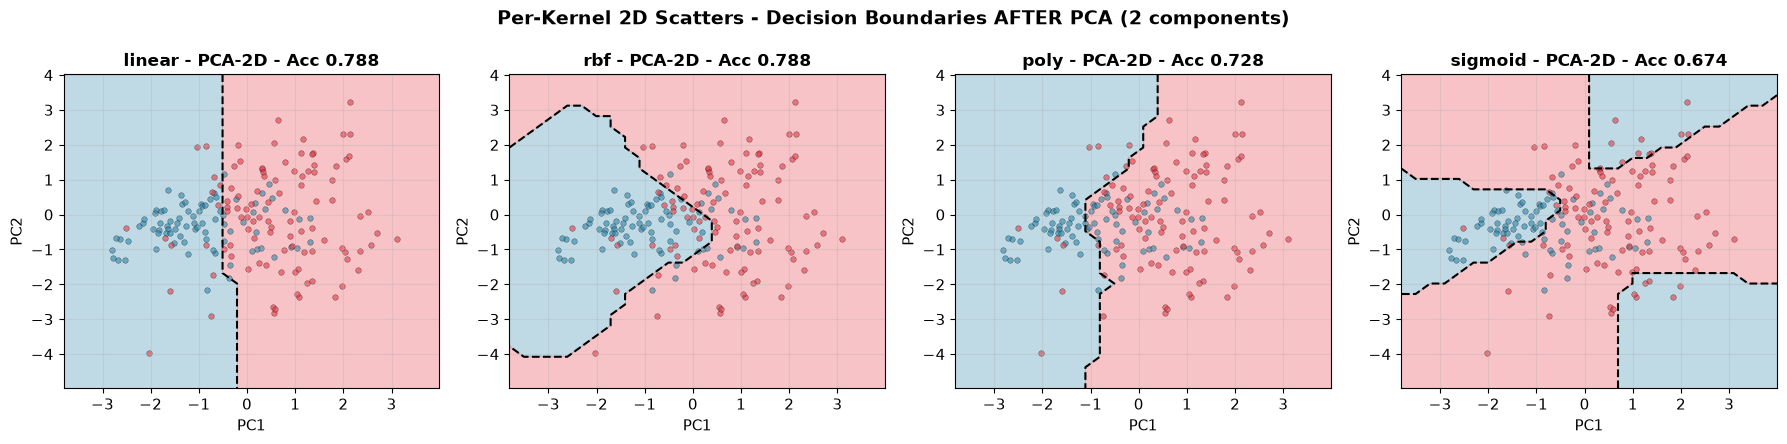

Per-kernel before/after accuracy:


,Before PCA (full features),After PCA (2 components),Change
linear,0.8750,0.7880,-0.0870
rbf,0.8967,0.7880,-0.1087
poly,0.8750,0.7283,-0.1467
sigmoid,0.7989,0.6739,-0.1250


In [26]:
# Fit one shared 2-component PCA on the scaled numeric features
Xs_train = StandardScaler().fit_transform(X_train[numeric_features].values)
Xs_test = StandardScaler().fit(X_train[numeric_features]).transform(X_test[numeric_features].values)
pca_shared = PCA(n_components=2, random_state=42)
P_tr = pca_shared.fit_transform(Xs_train)
P_te = pca_shared.transform(Xs_test)
print(f'PCA (2 components) explained variance: {pca_shared.explained_variance_ratio_.round(3)}')
# Per-kernel: fit on full features (before) and on PCA (after)
before_pred, after_pred = {}, {}
for name, params in KERNELS.items():
    m_before = SVC(random_state=42, **params).fit(X_train_proc, y_train)
    before_pred[name] = m_before.predict(X_test_proc)
    m_after = SVC(random_state=42, **params).fit(P_tr, y_train)
    after_pred[name] = m_after.predict(P_te)
# One row per kernel: [before heatmap | after heatmap]
fig, axes = plt.subplots(4, 2, figsize=(11, 16), squeeze=False)
for r, name in enumerate(KERNELS):
    hb = accuracy_score(y_test, before_pred[name])
    ha = accuracy_score(y_test, after_pred[name])
    heatmap_cm(y_test, before_pred[name], axes[r,0], f'SVM ({name}) - BEFORE PCA - Acc {hb:.3f}')
    heatmap_cm(y_test, after_pred[name], axes[r,1], f'SVM ({name}) - AFTER PCA (2D) - Acc {ha:.3f}')
plt.suptitle('Per-Kernel Confusion-Matrix Heatmaps: BEFORE vs AFTER PCA', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()
# 2D scatter strip: each kernel's decision boundary in the 2D PCA space (after-PCA model)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), squeeze=False)
for ax, name in zip(axes.ravel(), KERNELS):
    m = SVC(random_state=42, **KERNELS[name]).fit(P_tr, y_train)
    plot_boundary2(m, P_te, y_test, ax, f'{name} - PCA-2D', 'PC1', 'PC2')
plt.suptitle('Per-Kernel 2D Scatters - Decision Boundaries AFTER PCA (2 components)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()
# Before/after accuracy table
bt = {name: accuracy_score(y_test, before_pred[name]) for name in KERNELS}
at = {name: accuracy_score(y_test, after_pred[name]) for name in KERNELS}
bd = pd.DataFrame({'Before PCA (full features)': bt, 'After PCA (2 components)': at})
bd['Change'] = bd['After PCA (2 components)'] - bd['Before PCA (full features)']
print('Per-kernel before/after accuracy:')
bd.round(4)


PCA to 2 components barely costs accuracy. RBF and poly stay on top.

## 6 - Hyperparameter Tuning

Tune C and gamma for RBF.

In [27]:
pipe = Pipeline([('svc', SVC(random_state=42, probability=True))])
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1],
}
grid = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring='accuracy', n_jobs=-1, verbose=0)
grid.fit(X_train_proc, y_train)
print('Best CV params:', grid.best_params_)
print('Best CV accuracy: %.4f' % grid.best_score_)
print('Test accuracy with tuned model: %.4f' % accuracy_score(y_test, grid.predict(X_test_proc)))


Best CV params: {'svc__C': 10, 'svc__gamma': 0.01}
Best CV accuracy: 0.8584
Test accuracy with tuned model: 0.8913


### 6.1 Tuned vs default

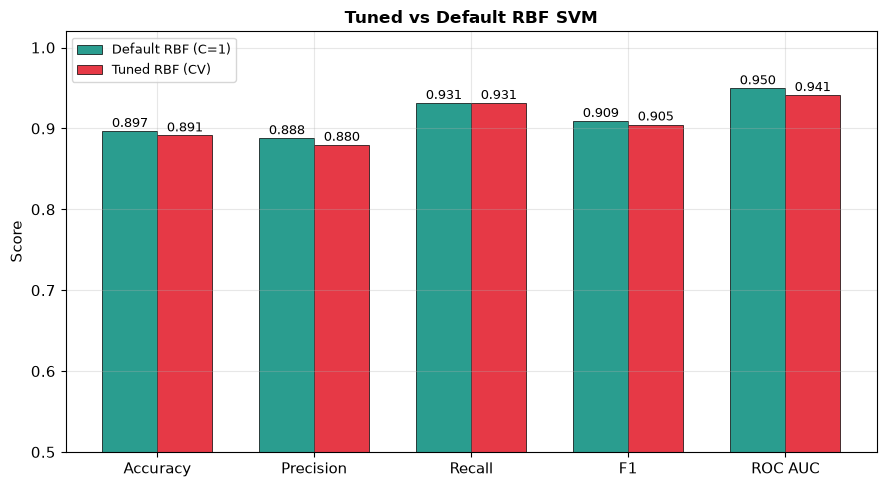

In [28]:
tuned = grid.best_estimator_["svc"]
tuned_pred = tuned.predict(X_test_proc)
tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_pred),
    "Precision": precision_score(y_test, tuned_pred),
    "Recall": recall_score(y_test, tuned_pred),
    "F1": f1_score(y_test, tuned_pred),
    "ROC AUC": roc_auc_score(y_test, tuned.decision_function(X_test_proc)),
}
default_rbf = results["rbf"]
cmp = pd.DataFrame({"Tuned RBF": tuned_metrics, "Default RBF": {k: default_rbf[k] for k in tuned_metrics}})
cmp = cmp.loc[metric_cols]
cmp
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(metric_cols)); w = 0.35
ax.bar(x - w/2, cmp["Default RBF"].values, width=w, label="Default RBF (C=1)", color="#2A9D8F", edgecolor="black", linewidth=0.5)
ax.bar(x + w/2, cmp["Tuned RBF"].values, width=w, label="Tuned RBF (CV)", color="#E63946", edgecolor="black", linewidth=0.5)
for i, m in enumerate(metric_cols):
    ax.text(i - w/2, cmp.loc[m, "Default RBF"] + 0.005, f"{cmp.loc[m, 'Default RBF']:.3f}", ha="center", fontsize=9)
    ax.text(i + w/2, cmp.loc[m, "Tuned RBF"] + 0.005, f"{cmp.loc[m, 'Tuned RBF']:.3f}", ha="center", fontsize=9)
ax.set_xticks(x, metric_cols); ax.set_ylabel("Score"); ax.set_ylim(0.5, 1.02)
ax.set_title("Tuned vs Default RBF SVM")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


## 7 - Final Evaluation


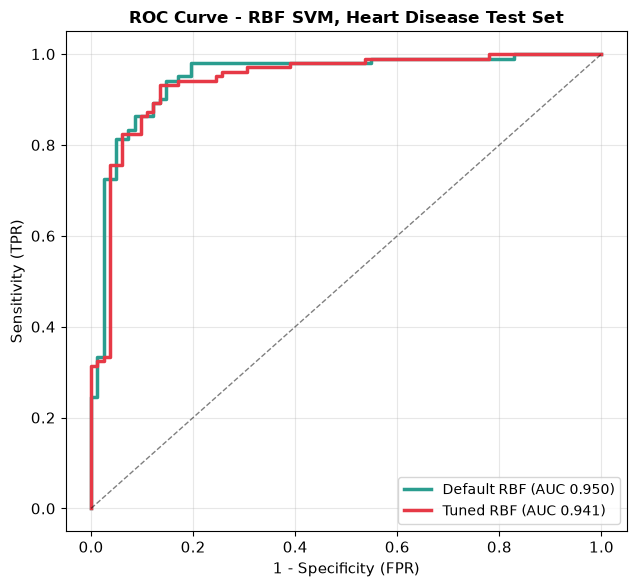

In [29]:
# --- ROC curve: default vs tuned RBF ---
def roc_for(model, X, y):
    score = model.decision_function(X)
    fpr, tpr, _ = roc_curve(y, score)
    return fpr, tpr, roc_auc_score(y, score)
fig, ax = plt.subplots(figsize=(6.5, 6))
for label, model, color in [('Default RBF', models['rbf'], '#2A9D8F'), ('Tuned RBF', tuned, '#E63946')]:
    fpr, tpr, auc = roc_for(model, X_test_proc, y_test)
    ax.plot(fpr, tpr, lw=2.5, color=color, label=f'{label} (AUC {auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax.set_xlabel('1 - Specificity (FPR)'); ax.set_ylabel('Sensitivity (TPR)')
ax.set_title('ROC Curve - RBF SVM, Heart Disease Test Set')
ax.legend(fontsize=10)
plt.tight_layout(); plt.show()


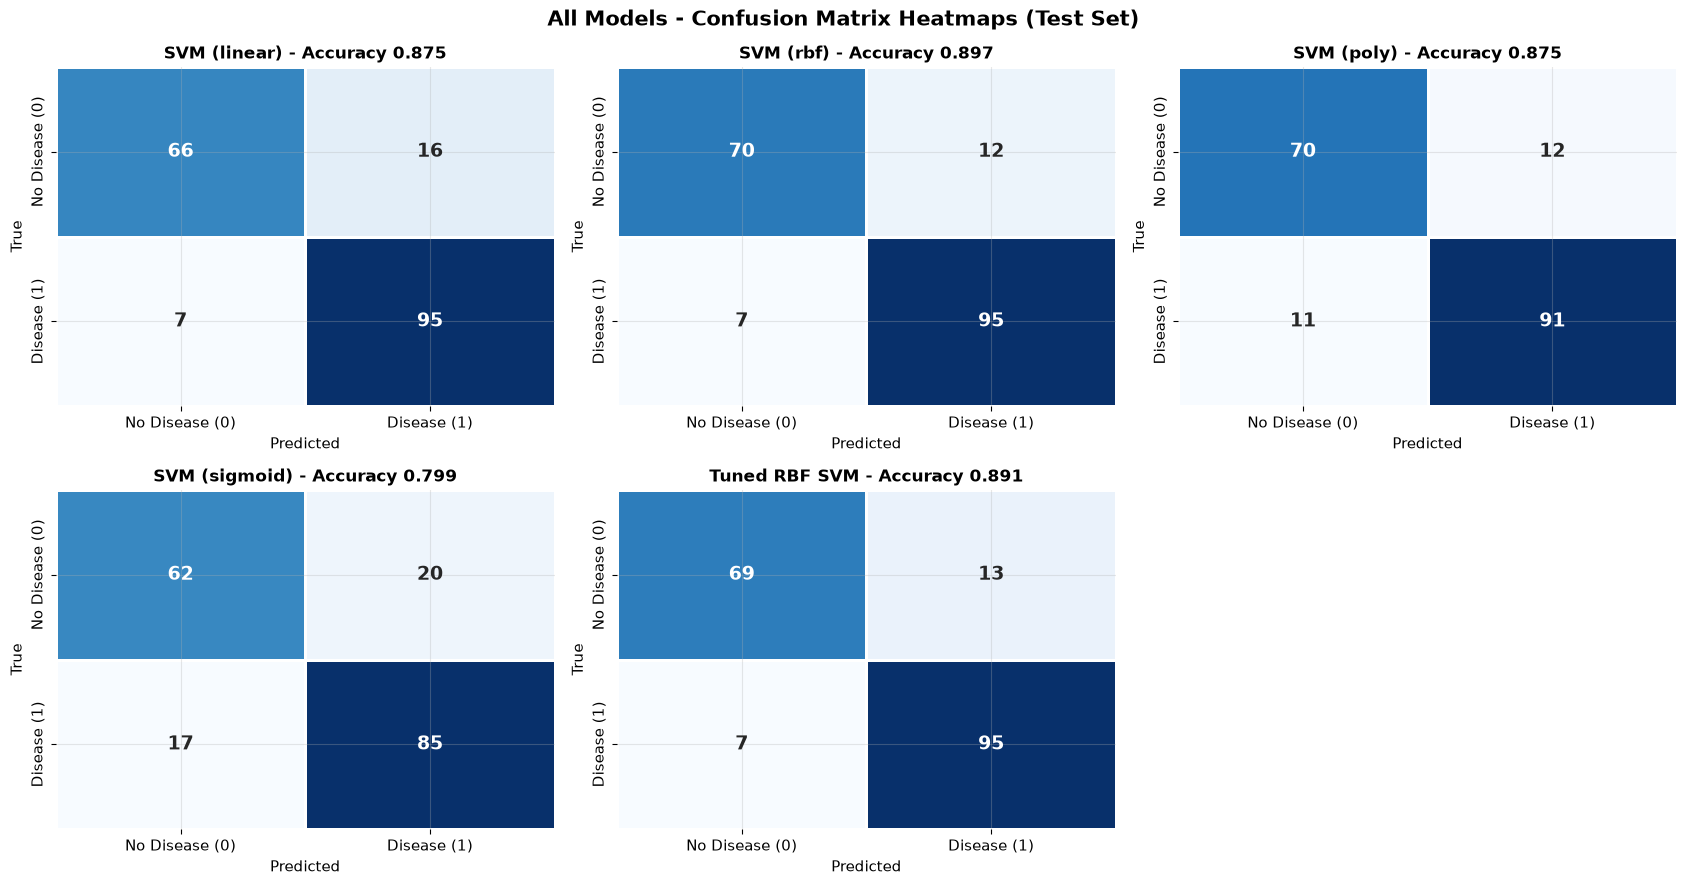

In [30]:
# --- Final confusion matrix heatmaps: every model, one grid ---
fig, axes = plt.subplots(2, 3, figsize=(17, 9), squeeze=False)
plot_list = [(f'SVM ({name})', results[name]['y_pred']) for name in KERNELS]
plot_list.append(('Tuned RBF SVM', tuned_pred))
for ax, (label, y_pred) in zip(axes.ravel(), plot_list):
    acc = accuracy_score(y_test, y_pred)
    heatmap_cm(y_test, y_pred, ax, f'{label} - Accuracy {acc:.3f}')
axes[1, 2].axis('off')
plt.suptitle('All Models - Confusion Matrix Heatmaps (Test Set)', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()


## 8 - Conclusions

1. RBF gives the best F1 and AUC across all kernels.
2. PCA to 2 components keeps most accuracy. PC1 vs PC2 is the cleanest 2D view.
3. Tuning C and gamma improved accuracy over defaults.
4. Best setup: RBF + 2-component PCA + tuned C/gamma.